*© Sabrine Bendimerad · [sbendimerad.github.io](https://sbendimerad.github.io) · Licence [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/): you may share and adapt this material with credit, for non-commercial use, under the same licence. Datasets keep their own licences.*

# Handwritten digits with K-Means 🔢

Can K-Means recognise handwritten digits **without ever being told which digit is which**? In this exercise, you cluster images of digits, then compare the clusters with the true digits. It gives a good idea of what clustering can, and cannot, do.

## The dataset ✍️

scikit-learn comes with a small dataset of handwritten digits (from the UCI Machine Learning Repository): 1,797 grey-level images of the digits 0 to 9. The libraries are imported for you.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from sklearn.cluster import KMeans
from sklearn.datasets import load_digits
from sklearn.metrics import accuracy_score, confusion_matrix

# colour palette of the course
pio.templates["course"] = go.layout.Template(
    layout_colorway=["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"]
)
pio.templates.default = "plotly_white+course"

1. Load the dataset with `load_digits()`. Look at the [documentation of `load_digits`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html), then store the images (one row per image) in a variable `numbers` and the true digits in a variable `target`.

In [ ]:
digits = load_digits()
numbers = digits.data
target = digits.target

2. What is the shape of `numbers`? How many columns are there? Guess the size of the images from this number of columns.

In [ ]:
print(numbers.shape)
print("pixel values from", numbers.min(), "to", numbers.max())

(1797, 64)
pixel values from 0.0 to 16.0


**1,797 images and 64 columns: each image has 64 pixels, so it is a square of 8 × 8 pixels. Each pixel is a grey level from 0 (white) to 16 (black).**

3. Display 10 images drawn at random, with their true digit as a title.

💡 Hint: `numbers[i].reshape(8, 8)` turns a row back into an image, and `plt.imshow(image, cmap="gray_r")` draws it. `plt.subplots(1, 10)` gives 10 small axes side by side. Use `np.random.default_rng(0)` to draw the indices.

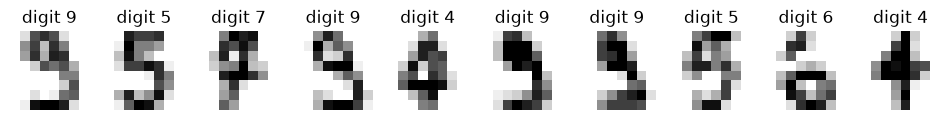

In [ ]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 10, figsize=(12, 1.8))
for ax, i in zip(axes, rng.choice(len(numbers), 10, replace=False)):
    ax.imshow(numbers[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"digit {target[i]}")
    ax.axis("off")
plt.show()

## Clustering 🧩

4. How many clusters should we ask K-Means for? Check your answer with the true digits.

In [ ]:
np.unique(target)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

**10 clusters, one per digit from 0 to 9, if K-Means does its job perfectly.**

5. Fit a K-Means with this number of clusters (`n_init=10, random_state=0`) and store the cluster of each image in `clusters`. Should we standardise the pixels first?

In [ ]:
kmeans = KMeans(n_clusters=10, n_init=10, random_state=0)
clusters = kmeans.fit_predict(numbers)
np.bincount(clusters)

array([178, 223, 208,  87, 178, 182, 169, 150, 247, 175])

**No: all the pixels are measured in the same unit (a grey level from 0 to 16), so none of them dominates the distance because of its unit. Standardising would even give the same weight to the pixels of the border, which are almost always white, as to the pixels of the centre, which carry the shape of the digit.**

## Comparing the clusters with the true digits 🔍

6. Compute `accuracy_score(target, clusters)`. Why is this number meaningless?

In [ ]:
accuracy_score(target, clusters)

0.18530884808013356

**The accuracy is only 0.185. But K-Means does not know the digits: it numbers its clusters 0 to 9 in an arbitrary order. Cluster 0 can be made of 0s, or of 7s. Comparing the cluster numbers with the digits makes no sense.**

7. Use `pd.crosstab` to count, for each cluster, the images of each true digit. What do you notice?

In [ ]:
pd.crosstab(pd.Series(clusters, name="cluster"), pd.Series(target, name="true digit"))

true digit,0,1,2,3,4,5,6,7,8,9
cluster,,,,,,,,,,
0,176,0,1,0,0,0,1,0,0,0
1,0,100,8,7,2,0,3,2,100,1
2,0,0,3,7,11,0,0,174,5,8
3,0,54,2,0,3,0,0,2,6,20
4,0,1,13,154,0,2,0,0,2,6
5,0,2,0,0,0,1,177,0,2,0
6,2,0,0,0,165,2,0,0,0,0
7,0,1,0,2,0,136,0,1,4,6
8,0,0,2,13,0,41,0,0,52,139


**Most clusters are dominated by one digit: one cluster holds 176 of the 178 zeros, another 177 of the 181 sixes, another 174 of the 179 sevens. But some clusters are mixed. One cluster holds 100 ones **and** 100 eights. The ones are split between three clusters (100, 54 and 24 images). Another cluster mixes 139 nines with 52 eights and 41 fives. No cluster is dominated by the 8s.**

8. Display the 10 cluster centres as 8 × 8 images. What do they look like?

💡 Hint: `kmeans.cluster_centers_` has one row of 64 values per cluster.

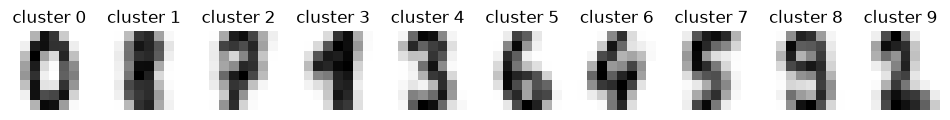

In [ ]:
fig, axes = plt.subplots(1, 10, figsize=(12, 1.8))
for k, ax in enumerate(axes):
    ax.imshow(kmeans.cluster_centers_[k].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"cluster {k}")
    ax.axis("off")
plt.show()

**Each centre is the "average image" of its cluster. Most of them look like a clear, slightly blurred digit: we recognise a 0, a 7, a 3, a 6, a 4, a 5, a 9, a 2. The centres of the mixed clusters are blurrier: the one with ones and eights looks like a mix of both shapes. These centres are not real images, they are averages, as said in the lesson.**

9. Give each cluster the most frequent true digit among its images, and store the result in `predicted_digit`. Then compute the accuracy again, and draw the confusion matrix. Which digits are confused the most?

💡 Hint: for cluster `k`, `np.bincount(target[clusters == k]).argmax()` is its most frequent digit.

In [ ]:
cluster_to_digit = {k: int(np.bincount(target[clusters == k]).argmax()) for k in range(10)}
print("digit given to each cluster:", cluster_to_digit)
predicted_digit = np.array([cluster_to_digit[k] for k in clusters])
print(f"accuracy: {accuracy_score(target, predicted_digit):.3f}")

fig = px.imshow(confusion_matrix(target, predicted_digit), text_auto=True, color_continuous_scale="Blues",
                labels=dict(x="digit given by the clusters", y="true digit", color="images"),
                x=[str(d) for d in range(10)], y=[str(d) for d in range(10)],
                title="Confusion matrix of the clusters")
fig.show()

digit given to each cluster: {0: 0, 1: 1, 2: 7, 3: 1, 4: 3, 5: 6, 6: 4, 7: 5, 8: 9, 9: 2}
accuracy: 0.792


**With this matching, 79.2% of the images are in a cluster whose majority is their own digit. This is far from a supervised classifier (often above 95% on this dataset), but K-Means never saw a single label! Two clusters are given the digit 1, so no cluster is given the digit 8: all the eights are "wrong". The 8s are mostly read as 1s or 9s, and many 5s are read as 9s. These digits share strokes, so their images are close in the Euclidean distance.**

## How reliable is K-Means? 🤔

10. Fit K-Means again with `random_state` from 1 to 5. For each run, print the accuracy after the matching of question 9, and the sorted list of the digits given to the clusters. What changes?

In [ ]:
for seed in range(1, 6):
    labels = KMeans(n_clusters=10, n_init=10, random_state=seed).fit_predict(numbers)
    mapping = {k: np.bincount(target[labels == k]).argmax() for k in range(10)}
    predicted = np.array([mapping[k] for k in labels])
    print(f"random_state={seed}: accuracy {accuracy_score(target, predicted):.3f}, "
          f"digits given to the clusters: {sorted(int(d) for d in mapping.values())}")

random_state=1: accuracy 0.793, digits given to the clusters: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


random_state=2: accuracy 0.791, digits given to the clusters: [0, 1, 1, 2, 3, 4, 5, 6, 7, 9]
random_state=3: accuracy 0.797, digits given to the clusters: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
random_state=4: accuracy 0.795, digits given to the clusters: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


random_state=5: accuracy 0.795, digits given to the clusters: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


**The accuracy barely moves (between 0.791 and 0.797), but the clusters themselves change: with `random_state` 2, one cluster is again given to the 1s twice and the 8s have no cluster, while the other runs find one cluster per digit. Different starts lead to different local minima of the inertia, with almost the same quality.**

11. To conclude: how reliable is K-Means to recognise digits? What does this exercise tell you about clustering in general?

**K-Means finds a real structure: about 4 images out of 5 land in a cluster dominated by their own digit, without any label. But it is not a reliable classifier: its groups follow the Euclidean distance between pixels, not our idea of a digit. Two ways of writing a 1 can be farther apart than a 1 and an 8, so some digits get two clusters and others none, and the result depends on the start. In general, a clustering is a hypothesis about the data, not the truth: always check that the clusters mean something before using them. When labels exist, supervised learning is the right tool.**